In [1]:
import stim

In [20]:
"""Written out Shor Code."""
# Will have to be looped, so will be written with circuit.append() methods
# Has yet to be tested
# Circuit-level noise errors have yet to be implemented.

circuit = stim.Circuit('''

# Initialize all data qubits (0-8) and the ancilla qubit (9)

R 0 1 2 3 4 5 6 7 8 9
CX 0 3
CX 0 6
H 0 3 6
CX 0 1
CX 3 4
CX 6 7
CX 0 2
CX 3 5
CX 6 8
TICK

# Encode for errors using noise

# Value of p in DEPOLARIZE is a placeholder.
DEPOLARIZE1(0.5) 0 1 2 3 4 5 6 7 8
TICK

# Bit flip stabilizers

# Z0Z1
CX 0 9
CX 1 9
MR 9
DETECTOR rec[-1]
TICK

# Z1Z2
CX 1 9
CX 2 9
MR 9
DETECTOR rec[-1]
TICK

# Z3Z4
CX 3 9
CX 4 9
MR 9
DETECTOR rec[-1]
TICK

# Z4Z5
CX 4 9
CX 5 9
MR 9
DETECTOR rec[-1]
TICK

# Z6Z7
CX 6 9
CX 7 9
MR 9
DETECTOR rec[-1]
TICK

# Z7Z8
CX 7 9
CX 8 9
MR 9
DETECTOR rec[-1]
TICK

# Phase flip stabilizers

# X0X1X2X3X4X5
H 0 1 2 3 4 5
CX 0 9
CX 1 9
CX 2 9
CX 3 9
CX 4 9
CX 5 9
H 0 1 2 3 4 5
MR 9
DETECTOR rec[-1]
TICK

# X3X4X5X6X7X8
H 3 4 5 6 7 8
CX 3 9
CX 4 9
CX 5 9
CX 6 9
CX 7 9
CX 8 9
H 3 4 5 6 7 8
MR 9
DETECTOR rec[-1]
TICK
'''
)

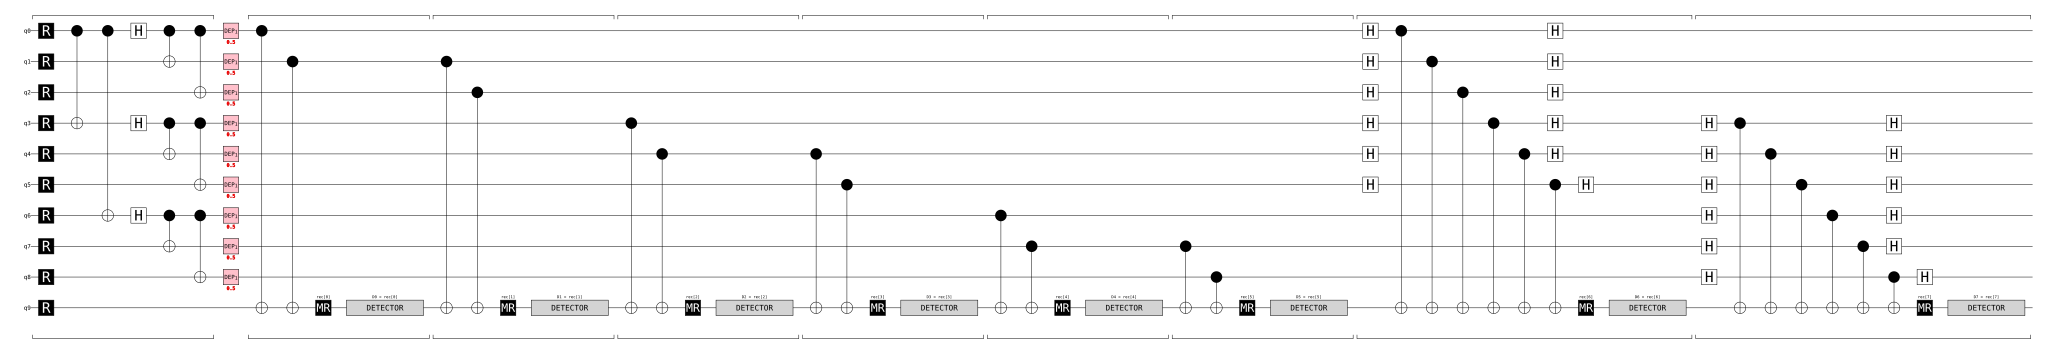

In [21]:
"""Circuit diagram for Shor code."""

circuit.diagram('timeline-svg')

In [22]:
"""Returns the detector measurements from the Shor code."""

runs = 100

sampler = circuit.compile_detector_sampler()
print(sampler.sample(shots=runs))

[[ True  True  True  True False  True  True  True]
 [ True  True  True False False False  True  True]
 [False  True False False  True  True  True False]
 [ True False  True  True False False  True  True]
 [ True False False False False False  True False]
 [ True False  True False  True False False  True]
 [False False False  True  True False  True  True]
 [False False  True False False False  True  True]
 [ True False False  True False False False  True]
 [ True  True False False  True False False  True]
 [ True False  True False False False False False]
 [False False False False  True  True  True False]
 [ True False False False False  True False  True]
 [False  True  True False False  True False  True]
 [False  True  True False False False  True False]
 [False  True  True False False False  True False]
 [False  True  True  True  True  True  True False]
 [ True False False False False False  True False]
 [ True  True False False False False False False]
 [False  True False False False